# Learned scATAC embeddings: LSI, scBasset and PeakVI

LSI (TF-IDF followed by SVD) is the standard linear embedding of a cell × peak
matrix. This tutorial compares it with two learned embeddings, on the ATAC part
of the 10x PBMC 10k Multiome sample (9,631 cells with Seurat-WNN cell-type labels):

| method | function | idea |
|---|---|---|
| LSI | `epi.tl.lsi` | TF-IDF, then a truncated SVD |
| scBasset | `epi.tl.scbasset` | a CNN reads the 1,344 bp under each peak and predicts its accessibility in every cell. Each cell's weights in the last layer are its embedding (Yuan & Kelley, Nat Methods 2022). |
| PeakVI | `epi.tl.peakvi` | a variational autoencoder of binarised peak counts (Ashuach *et al.*, Nat Methods 2022) |

`epi.tl.scbasset` runs `epione.models.scbasset`, a PyTorch rewrite of the
official TensorFlow code (calico/scBasset). It keeps the official layers,
initialisation and training recipe, imports no TensorFlow, and loads official
`.h5` weights. `epi.tl.peakvi` wraps scvi-tools `PEAKVI`, the authors' own
implementation.

Both models need `pip install 'epione[multimodal]'` (torch, scvi-tools) and a
GPU for practical run times. scBasset also needs the genome sequence;
`epi.data.hg38` downloads it on first use.

In [1]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import scipy.sparse as sp
import scanpy as sc
import matplotlib.pyplot as plt
import epione as epi
from epione.models import scbasset as sb

sc.settings.verbosity = 0
DATA = os.environ.get("EPIONE_PBMC10K_DIR")              # None -> pooch cache
WORK = Path(os.environ.get("EPIONE_ATAC_EMBED_WORK", "atac_embedding_work"))
WORK.mkdir(exist_ok=True, parents=True)
GENOME = os.environ.get("EPIONE_HG38_FASTA") or epi.data.hg38
MOTIFS = os.environ.get("EPIONE_SCBASSET_MOTIFS")         # None -> download (306 MB)

## Data and peak filter

scBasset's PBMC multiome example, and scvi-tools' PeakVI tutorial, keep the
peaks that are accessible in more than 5 % of cells. We also keep only
chr1-22, X and Y. This leaves about 29,500 of the 107,194 peaks. All three
methods use this matrix.

In [2]:
_, atac = epi.datasets.pbmc10k_multiome(DATA)
X = sp.csr_matrix(atac.X)
n_cells_per_peak = np.diff(X.tocsc().indptr)
chroms = [f"chr{i}" for i in range(1, 23)] + ["chrX", "chrY"]
keep = (n_cells_per_peak > int(0.05 * atac.n_obs)) & atac.var["chrom"].astype(str).isin(chroms).to_numpy()
atac = atac[:, keep].copy()
atac.X = sp.csr_matrix(atac.X, dtype=np.float32)
print(atac.shape, atac.obs["cell_type"].nunique(), "cell types")

(9631, 29542) 19 cell types


## LSI

TF-IDF and a 50-component SVD; the first component tracks sequencing depth
and is dropped.

In [3]:
epi.tl.lsi(atac, n_components=50)
atac.obsm["X_lsi"].shape

  └─ Starting optimized LSI analysis...
  └─ Computing TF-IDF normalization...


  └─ Applying L1 normalization and log transformation...


  └─ Performing randomized SVD...


  └─ Standardizing embeddings...
  └─ Removing first component (typically associated with peak count per cell)
  └─ LSI analysis completed!


(9631, 49)

## scBasset

`epi.tl.scbasset` extracts the 1,344 bp centred on each peak from the genome
FASTA and binarises the counts. It splits the peaks 90/5/5 into training,
test and validation sets, as the official preprocessing does, then trains with
the official recipe: batches of 128 peaks, Adam at lr 0.01, early stopping on
the training AUC with patience 50, and the best epoch kept. The defaults are the official ones,
up to 1,000 epochs. Here we cap training at 200 epochs, the budget used for
the parity runs below. That takes about 1.2 h on a shared H100, so the trained
model is cached in `WORK`.

In [4]:
ckpt = WORK / "scbasset_s0.pt"
peaks = sb.peak_table(atac.var)
codes = sb.peak_sequences(peaks, GENOME)
if ckpt.exists():
    model = sb.ScBasset(codes, atac.X).load(ckpt)
    atac.obsm["X_scbasset"] = model.cell_embedding()
    atac.obs["scbasset_intercept"] = model.intercept()
else:
    model = epi.tl.scbasset(atac, codes=codes, max_epochs=200, seed=0, log_every=20)
    model.save(ckpt)
h = model.history
print(f"{h['epochs_run']} epochs, best epoch {h['best_epoch'] + 1}, "
      f"training AUC {max(h['auc']):.3f}")
print(f"held-out peaks: mean per-cell AUROC {np.nanmean(model.test_auroc()):.3f}")

200 epochs, best epoch 196, training AUC 0.805


held-out peaks: mean per-cell AUROC 0.667


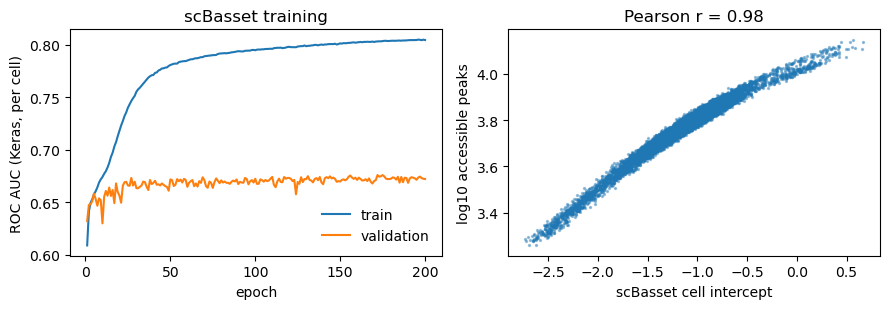

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
axes[0].plot(np.arange(1, len(h["auc"]) + 1), h["auc"], label="train")
axes[0].plot(np.arange(1, len(h["val_auc"]) + 1), h["val_auc"], label="validation")
axes[0].set(xlabel="epoch", ylabel="ROC AUC (Keras, per cell)", title="scBasset training")
axes[0].legend(frameon=False)
depth = np.log10(np.asarray((atac.X > 0).sum(axis=1)).ravel())
axes[1].scatter(atac.obs["scbasset_intercept"], depth, s=2, alpha=0.4)
r = np.corrcoef(atac.obs["scbasset_intercept"], depth)[0, 1]
axes[1].set(xlabel="scBasset cell intercept", ylabel="log10 accessible peaks", title=f"Pearson r = {r:.2f}")
plt.tight_layout()

The cell intercept absorbs sequencing depth, as in the paper. This leaves
the 32-dimensional embedding free to encode cell state.

## PeakVI

`epi.tl.peakvi` trains scvi-tools' PeakVI with its defaults: up to 500
epochs with early stopping, hidden layers of √n_peaks units (171 here) and a
latent space of √171 ≈ 13 dimensions. The latent mean goes to
`obsm["X_peakvi"]`, and the trained model is returned.

In [6]:
pv = epi.tl.peakvi(atac, seed=0)
atac.obsm["X_peakvi"].shape

[rank: 0] Seed set to 0


GPU available: True (cuda), used: True


TPU available: False, using: 0 TPU cores


💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


You are using a CUDA device ('NVIDIA H100 80GB HBM3') that has Tensor Cores. To properly utilize them, you should set `torch.set_float32_matmul_precision('medium' | 'high')` which will trade-off precision for performance. For more details, read https://pytorch.org/docs/stable/generated/torch.set_float32_matmul_precision.html#torch.set_float32_matmul_precision


...

SLURM auto-requeueing enabled. Setting signal handlers.


/scratch/users/steorra/envs/epi-higashi/lib/python3.11/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=5` in the `DataLoader` to improve performance.
/scratch/users/steorra/envs/epi-higashi/lib/python3.11/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=5` in the `DataLoader` to improve performance.


Training:   0%|          | 0/500 [00:00<?, ?it/s]

Monitored metric reconstruction_loss_validation did not improve in the last 50 records. Best score: 11697.122. Signaling Trainer to stop.


(9631, 13)

## UMAPs and metrics

Each embedding gets a 15-NN graph, a Leiden clustering at resolution 1 and a
UMAP. We score them against the cell-type labels:

- ARI and AMI of the Leiden clusters;
- leave-one-out 15-NN cell-type accuracy;
- the cell-type silhouette.

These are the metrics of the parity gates.

In [7]:
from sklearn.metrics import adjusted_rand_score, adjusted_mutual_info_score, silhouette_score
from sklearn.neighbors import NearestNeighbors

def knn_accuracy(emb, labels, k=15):
    codes_, y = np.unique(labels, return_inverse=True)
    idx = NearestNeighbors(n_neighbors=k + 1).fit(emb).kneighbors(emb)[1][:, 1:]
    votes = np.zeros((len(y), len(codes_)), int)
    for j in range(k):
        np.add.at(votes, (np.arange(len(y)), y[idx[:, j]]), 1)
    return (votes.argmax(1) == y).mean()

ct = atac.obs["cell_type"].astype(str).to_numpy()
rows, reps = [], {"LSI": "X_lsi", "scBasset": "X_scbasset", "PeakVI": "X_peakvi"}
for name, rep in reps.items():
    sc.pp.neighbors(atac, use_rep=rep, n_neighbors=15, key_added=name, random_state=0)
    sc.tl.leiden(atac, resolution=1.0, neighbors_key=name, key_added=f"leiden_{name}",
                 flavor="igraph", n_iterations=2, directed=False, random_state=0)
    sc.tl.umap(atac, neighbors_key=name, random_state=0)
    atac.obsm[f"X_umap_{name}"] = atac.obsm["X_umap"].copy()
    E = atac.obsm[rep]
    rows.append({"embedding": name, "dims": E.shape[1],
                 "ARI": adjusted_rand_score(ct, atac.obs[f"leiden_{name}"]),
                 "AMI": adjusted_mutual_info_score(ct, atac.obs[f"leiden_{name}"]),
                 "kNN accuracy": knn_accuracy(E, ct),
                 "silhouette": silhouette_score(E, ct)})
metrics = pd.DataFrame(rows).set_index("embedding")
metrics.round(3)

,dims,ARI,AMI,kNN accuracy,silhouette
embedding,,,,,
LSI,49,0.699,0.804,0.931,0.041
scBasset,32,0.422,0.648,0.803,0.062
PeakVI,13,0.475,0.721,0.921,0.142


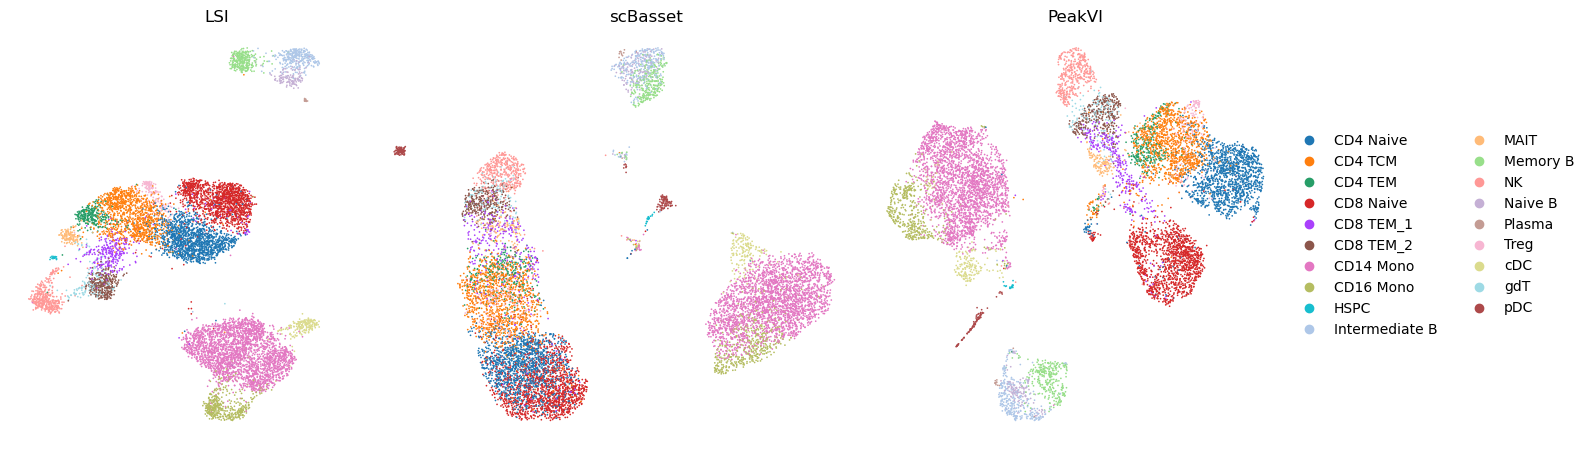

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
for ax, name in zip(axes, reps):
    sc.pl.embedding(atac, f"X_umap_{name}", color="cell_type", ax=ax, show=False, frameon=False,
                    title=name, legend_loc="none" if name != "PeakVI" else "right margin", s=6)
plt.tight_layout()

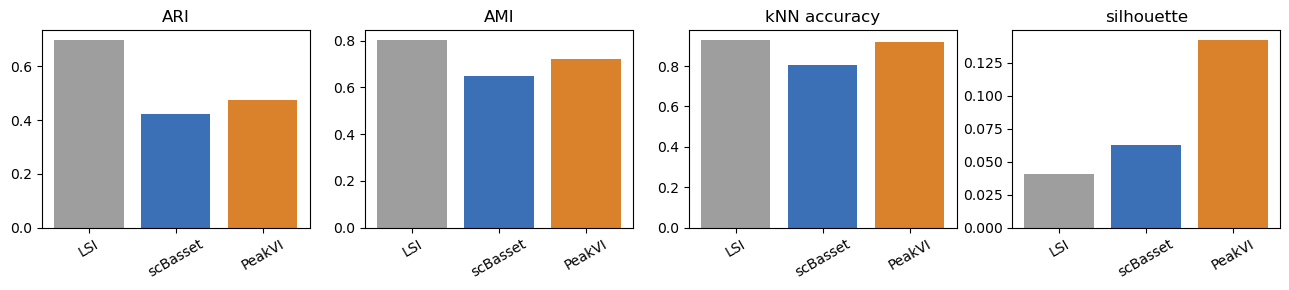

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(13, 3))
for ax, m in zip(axes, ["ARI", "AMI", "kNN accuracy", "silhouette"]):
    ax.bar(metrics.index, metrics[m], color=["#9e9e9e", "#3b6fb6", "#d9822b"])
    ax.set_title(m)
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()

On this matrix, with these labels, LSI gives the best clustering agreement
(ARI 0.70, kNN accuracy 0.93). PeakVI comes close on kNN accuracy (0.92) and
has the most compact cell types (silhouette 0.14). scBasset, capped at 200
epochs, trails both (ARI 0.42). The labels are Seurat-WNN annotations that
used RNA as well as ATAC, and scBasset was trained for a fifth of the paper's
budget, so this ranking is not a verdict on the methods.

## Denoised accessibility

scBasset's depth-normalised prediction is the sigmoid of the sequence
embedding times each cell's weights, without the intercept
(`model.impute()` / `model.predict(normalize=True)`). PeakVI's imputed
accessibility comes from `pv.get_normalized_accessibility()`. Below are the
peaks that PeakVI's differential accessibility test ranks first for CD14
monocytes and for NK cells, against all other cells.

DE...:   0%|          | 0/1 [00:00<?, ?it/s]

CD14 Mono chr13:74131800-74137006 {'prob_da': 0.996, 'effect_size': 0.848}


DE...:   0%|          | 0/1 [00:00<?, ?it/s]

NK chr11:61019116-61029418 {'prob_da': 0.967, 'effect_size': 0.553}


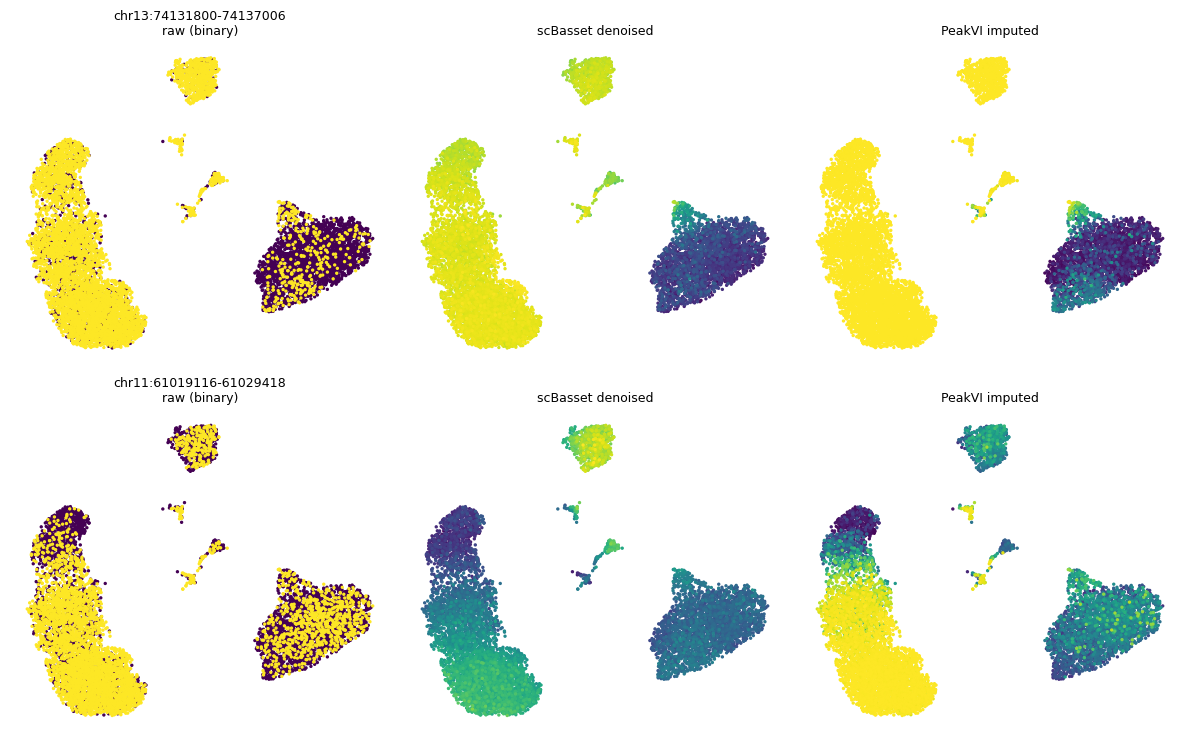

In [10]:
top = {}
for g in ["CD14 Mono", "NK"]:
    da = pv.differential_accessibility(groupby="cell_type", group1=g)
    top[g] = da.sort_values("effect_size", ascending=False).index[0]
    print(g, top[g], {k: round(float(da.loc[top[g], k]), 3) for k in ["prob_da", "effect_size"]})
names = list(top.values())
col = [atac.var_names.get_loc(n) for n in names]
pv_imp = pv.get_normalized_accessibility(region_list=names)
sb_imp = model.predict(idx=np.array(col), normalize=True).T          # cells x peaks
fig, axes = plt.subplots(2, 3, figsize=(12, 7.5))
for r, (g, n) in enumerate(top.items()):
    j = names.index(n)
    vals = {"raw (binary)": (np.asarray(atac.X[:, col[j]].todense()).ravel() > 0).astype(float),
            "scBasset denoised": sb_imp[:, j], "PeakVI imputed": pv_imp[n].to_numpy()}
    for c, (t, v) in enumerate(vals.items()):
        ax = axes[r, c]
        u = atac.obsm["X_umap_scBasset"]
        o = np.argsort(v)
        ax.scatter(u[o, 0], u[o, 1], c=v[o], s=2, cmap="viridis")
        ax.set_title(f"{n}\n{t}" if c == 0 else t, fontsize=9)
        ax.set_axis_off()
plt.tight_layout()

## TF activity by motif injection

scBasset scores a TF by inserting its motif into 1,000 dinucleotide-shuffled
peak sequences, predicting their accessibility in every cell, and
subtracting the prediction for the same sequences without the motif. The
score is z-scored over cells (`model.motif_score`). The motif library is the
official one (CIS-BP motifs, 733 human TFs), downloaded once and md5-checked.

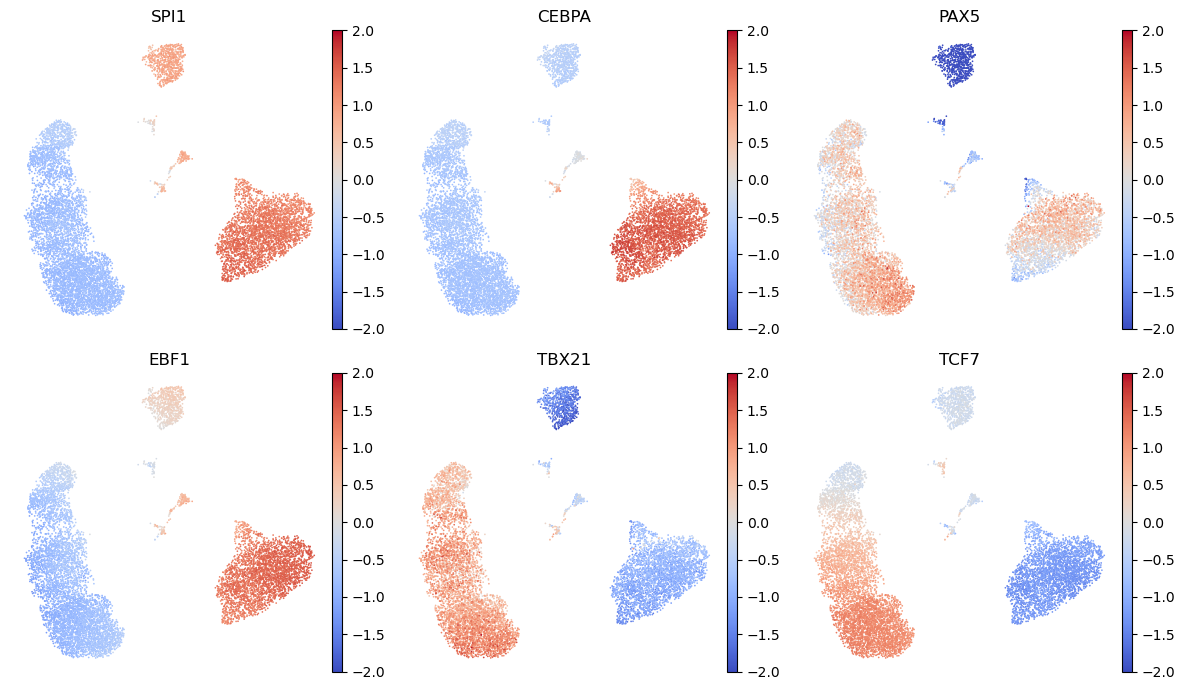

In [11]:
tfs = ["SPI1", "CEBPA", "PAX5", "EBF1", "TBX21", "TCF7"]
for t in tfs:
    atac.obs[f"{t}_activity"] = model.motif_score(t, motif_dir=MOTIFS)
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for ax, t in zip(axes.ravel(), tfs):
    sc.pl.embedding(atac, "X_umap_scBasset", color=f"{t}_activity", ax=ax, show=False, frameon=False,
                    cmap="coolwarm", vmin=-2, vmax=2, title=t, s=6)
plt.tight_layout()

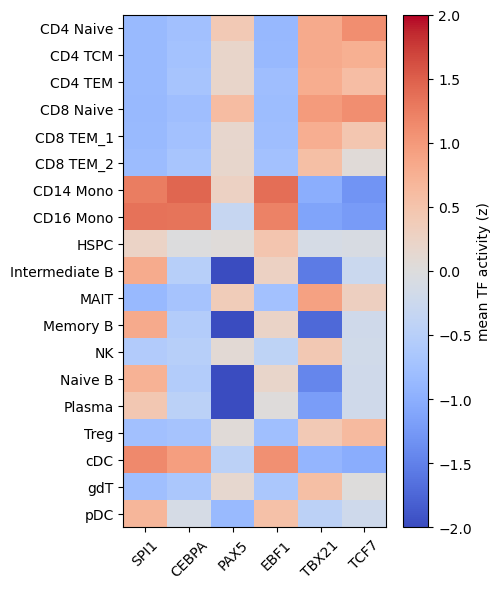

In [12]:
act = atac.obs[[f"{t}_activity" for t in tfs]].groupby(atac.obs["cell_type"], observed=True).mean()
act.columns = tfs
fig, ax = plt.subplots(figsize=(5, 6))
im = ax.imshow(act.to_numpy(), cmap="coolwarm", vmin=-2, vmax=2, aspect="auto")
ax.set_xticks(range(len(tfs)), tfs, rotation=45)
ax.set_yticks(range(len(act)), act.index)
plt.colorbar(im, ax=ax, label="mean TF activity (z)")
plt.tight_layout()

SPI1 and CEBPA score highest in monocytes and DCs. TCF7, and to a lesser
extent TBX21, score highest in T and NK cells. These patterns are the same for
every seed of both the official code and Epione.

The B-cell factors PAX5 and EBF1 are **not** stable at this training budget.
Across three seeds, the mean PAX5 score in B cells ranges from −2.0 to 0.2
with the official TensorFlow code and from −3.1 to 0.1 with Epione. Loaded
into Epione, official weights reproduce the official scores exactly (r = 1.0),
so the instability comes from the model, not from the port. The paper trained
for 1,000 epochs. For B-cell TFs, train to the default budget
(`max_epochs=1000`) and compare several seeds before reading these scores.

## Parity

`tests/parity/scbasset_peakvi/MANIFEST.md` holds the pre-registered gates and
their results on this data:

- **Preprocessing (G0).** Epione's preprocessing equals the official
  `scbasset_preprocess.py`: peak table, sequences, binary targets and split.
- **Architecture (G1c).** Official `best_model.h5` weights loaded into the
  PyTorch network reproduce the official predictions.
- **Training (G2).** Over three seeds per side, `epi.tl.scbasset` is compared
  with the official TensorFlow code on ARI, AMI, kNN accuracy, silhouette and
  held-out peak AUROC.
- **PeakVI.** `epi.tl.peakvi` matches direct scvi-tools calls exactly.